# Занятие 3. Основы python

## 📊 Задание 1

Абсолютную энтропию вещества можно найти по третьему началу термодинамики из
калориметрических данных: измеряют теплоёмкость от почти абсолютного нуля до
нужной температуры и интегрируют

$$S(T) = \int_0^{T} \frac{C_p}{T'}\,dT', \qquad
\Delta H = \int_0^{T} C_p\,dT'.$$

Для кристаллического серебра теплоёмкость измерена от 20 до 298 К (данные в
ячейке ниже). Ниже 20 К калориметр не может измерять, но этот участок неплохо описывается предельным
законом Дебая: $C_p = aT^3$.

Вам нужно:
* Интерполировать данные кубическим сплайном и построить график $C_p(T)$ в диапазоне $0-300 K$.
* Определить коэффициент $a$ по первым трём экспериментальным точкам и рассчитать $C_p(T)$ в диапазоне $0-20 K$. Наблюдается ли расхождение между кривой, рассчитанной по закону Дебая, и интерполированными данными?
* Рассчитать $\Delta H(0\!\to\!300)$ и зависимость $S(T)$, используя интерполированные данные в диапазоне $0-300 K$
* Сравнить полученную энтропию с табличным значением для серебра: $S^\circ_{298} = 42.55$ Дж/(моль·К).

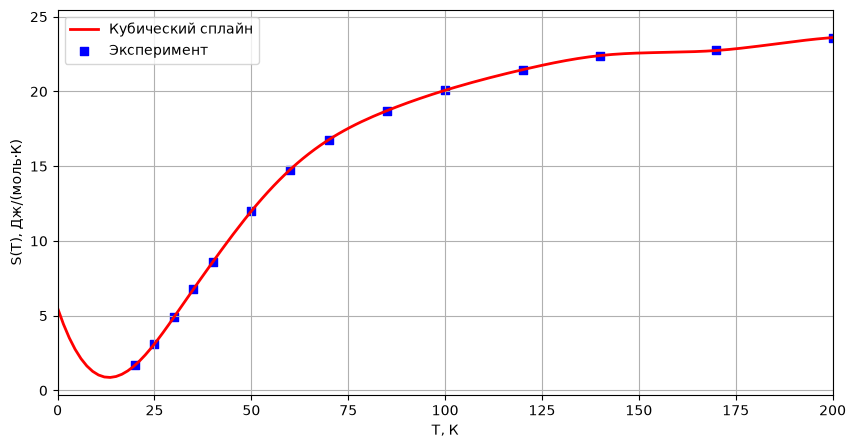

In [4]:
import numpy as np
from scipy import integrate
from scipy import interpolate
from scipy import optimize
import matplotlib.pyplot as plt

# Теплоёмкость кристаллического серебра, Дж/(моль·К)
T_exp  = np.array([20, 25, 30, 35, 40, 50, 60, 70, 85, 100,
                   120, 140, 170, 200, 230, 260, 298])
Cp_exp = np.array([1.694, 3.114, 4.891, 6.757, 8.581, 11.995, 14.770,
                   16.775, 18.714, 20.076, 21.455, 22.400, 22.739,
                   23.602, 23.712, 24.020, 24.239])
inter = interpolate.CubicSpline(T_exp, Cp_exp, bc_type='not-a-knot')
T_line = np.linspace(0, 300, 200)
Cp_line = inter(T_line)
plt.figure(figsize=(10, 5))
plt.plot(T_line, Cp_line, c = 'r', linewidth = 2, label = 'Кубический сплайн')
plt.scatter(T_exp, Cp_exp, marker = 's', c = 'b', label = 'Эксперимент')
plt.grid(True)
plt.xlabel('Т, К')
plt.ylabel(f'S(T), Дж/(моль·К)')
plt.xlim(0, 200)
plt.legend()
plt.show()


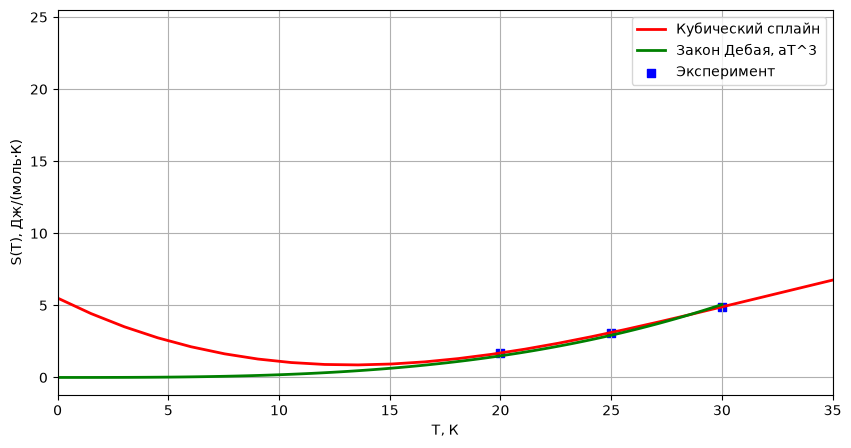

a = 1.8731e-04


In [247]:
def deb(x, a):
    return a*x**3
opt, cor = optimize.curve_fit(deb, T_exp[0:3], Cp_exp[0:3])
x_opt = np.linspace(0, 30, 100)
y_opt = deb(x_opt, *opt)
plt.figure(figsize=(10, 5))
plt.plot(T_line, Cp_line, c = 'r', linewidth = 2, label = 'Кубический сплайн')
plt.plot(x_opt, y_opt, c = 'g', linewidth = 2, label = 'Закон Дебая, аТ^3')
plt.scatter(T_exp[0:3], Cp_exp[0:3], marker = 's', c = 'b', label = 'Эксперимент')
plt.grid(True)
plt.xlabel('Т, К')
plt.ylabel(f'S(T), Дж/(моль·К)')
plt.xlim(0, 35)
plt.legend()
plt.show()
print(f'a = {float(opt[0]):.4e}')

Расхождение наблюдается, при том сильное. Это логично, т.к. при интерполяции кубическим сплайном полином 3й степени при отсутсвии данных начал загибаться.

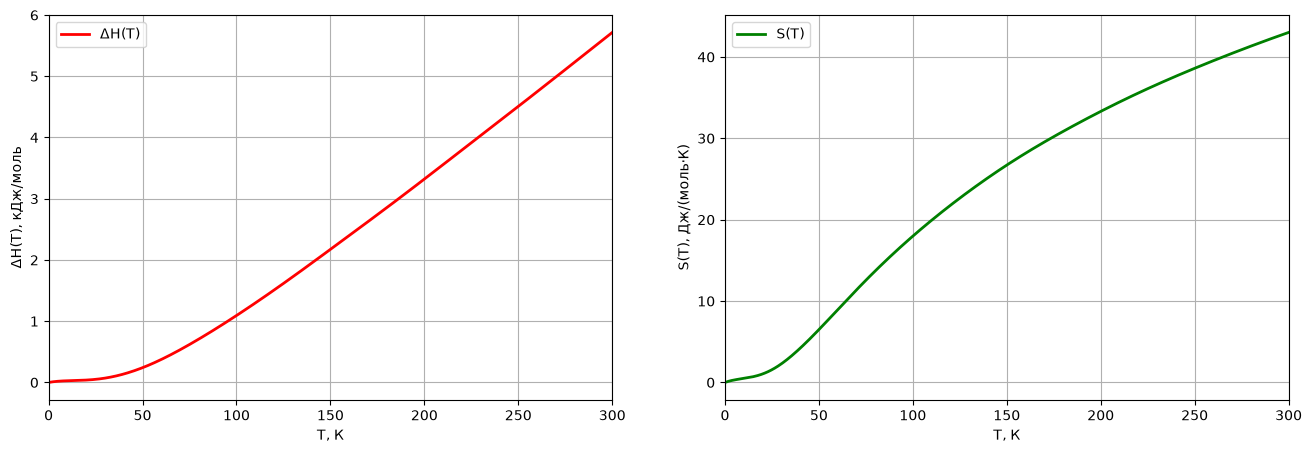

In [104]:
Cp_T = Cp_exp/T_exp
inter_forS = interpolate.CubicSpline(T_exp, Cp_T, bc_type='not-a-knot')

T_forHS = np.linspace(0, 300, 500)
H = []
S = []
for i in T_forHS:
    H.append((integrate.quad(inter, 0, i)[0])/1000)
    S.append(integrate.quad(inter_forS, 0, i)[0])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (16, 5))
ax1.plot(T_forHS, H, c = 'r', linewidth = 2, label = f'ΔH(T)')
ax2.plot(T_forHS, S, c = 'g', linewidth = 2, label = 'S(T)')
ax1.grid(True)
ax2.grid(True)
ax1.set_xlabel('Т, К')
ax2.set_xlabel('Т, К')
ax1.set_ylabel('ΔH(T), кДж/моль')
ax2.set_ylabel('S(T), Дж/(моль·К)')
ax1.set_xlim(0, 300)
ax2.set_xlim(0,300)
ax1.legend()
ax2.legend()
plt.show()

In [114]:

print(integrate.quad(inter_forS, 0, 298)[0])

42.84544558116917


Значение получилось близко к экспериментальному, и это с учетом, что мы в диапазоне 0-20 К работали не совсем честно (не используя закон Дебая)

## ⚙️ Задание 2


Метанол в промышленности может быть получен из синтез-газа. В реакторе одновременно устанавливаются два равновесия - синтез метанола и обратная паровая конверсия CO:

$$\text{(1)}\quad CO + 2H_2 \rightleftharpoons CH_3OH \qquad K_{p1} = 2.0\cdot10^{-4}\ \text{атм}^{-2}$$
$$\text{(2)}\quad CO_2 + H_2 \rightleftharpoons CO + H_2O \qquad K_{p2} = 1.2\cdot10^{-2}$$

(обе константы равновесия рассчитаны при $T_0 = 523$ К). В реактор загружают **1 моль CO, 1 моль CO₂ и 7 моль H₂** при общем давлении $P = 100$ атм. Пусть $x_1$ и $x_2$ — глубины реакций (1) и (2).

Вам нужно:
* Найти равновесный состав смеси (моли и мольные доли) при 523 К и 100 атм (используйте функцию `fsolve`).
* Построить график равновесной мольной доли CH₃OH от давления в диапазоне
  10-300 атм. Объяснить ход кривой с точки зрения принципа Ле Шателье.
* Тепловые эффекты реакций: $\Delta H_1 = -90.6$ кДж/моль,
  $\Delta H_2 = +41.2$ кДж/моль. По уравнению Вант-Гоффа
  $$K(T) = K(T_0)\,\exp\!\left[-\frac{\Delta H}{R}\left(\frac{1}{T}-\frac{1}{T_0}\right)\right]$$
  пересчитайте константы и постройте зависимость выхода метанола от
  температуры (450–600 К) при 100 атм.

In [243]:
import pandas as pd
def eq(v):
    x1, x2 = v
    return [2.0*10**-4 - (100**-2*(1/(9-2*x1))**-2*x1/((1-x1+x2)*(7-2*x1-x2)**2)),
    1.2*10**-2 - (x2*(1-x1+x2)/((1-x2)*(7-2*x1-x2)))]
start = [0.2, 0.2]
sol = optimize.fsolve(eq, start)
mol = pd.DataFrame()
mol['Вещество'] = ['CH3OH', 'CO', 'H2', 'CO2']
mol_s = [sol[0], 1-sol[0]+sol[1], 7-2*sol[0]-sol[1], 1-sol[1]]
mol['Мольный состав, моль'] = [sol[0], 1-sol[0]+sol[1], 7-2*sol[0]-sol[1], 1-sol[1]]
print(sol)
mol

[0.57501125 0.11337171]


,Вещество,"Мольный состав, моль"
0,CH3OH,0.575011
1,CO,0.538360
2,H2,5.736606
3,CO2,0.886628


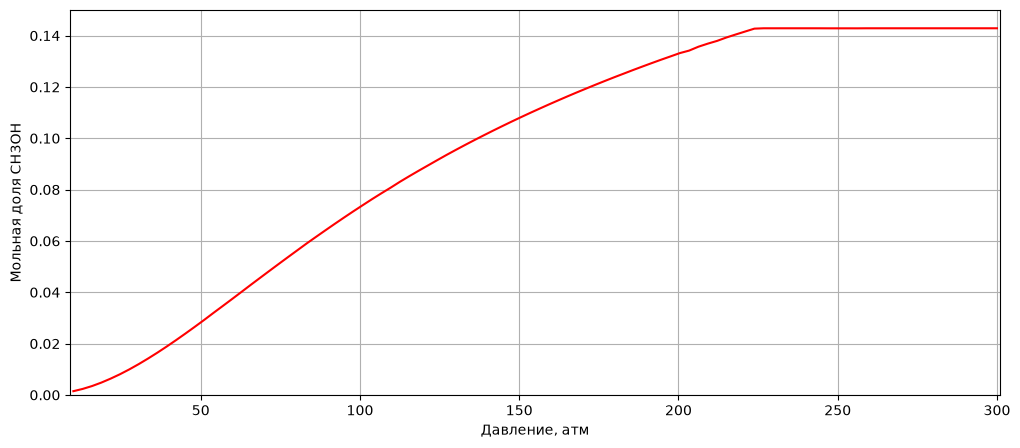

In [63]:
p = np.linspace(10, 300, 100)
sol_p = []
bounds = ([1e-6, 1e-6], [1, 1])
start = [0.2, 0.2]
for i in p:
    def eq2(v):
        x1, x2 = v
        return [2.0*10**-4 - (i**-2*(1/(9-2*x1))**-2*x1/((1-x1+x2)*(7-2*x1-x2)**2)), 1.2*10**-2 - (x2*(1-x1+x2)/((1-x2)*(7-2*x1-x2)))]
    sol2 = optimize.least_squares(eq2, start, bounds= bounds)
    sol_p.append(sol2.x[0]/(9-2*sol2.x[0]))
fig, ax = plt.subplots(figsize = (12,5))
ax.plot(p, sol_p, c = 'r', linewidth = 1.5)
ax.set_xlabel('Давление, атм')
ax.set_ylabel('Мольная доля CH3OH')
ax.grid(True)
ax.set_ylim(0,0.15)
ax.set_xlim(9, 301)
plt.show()

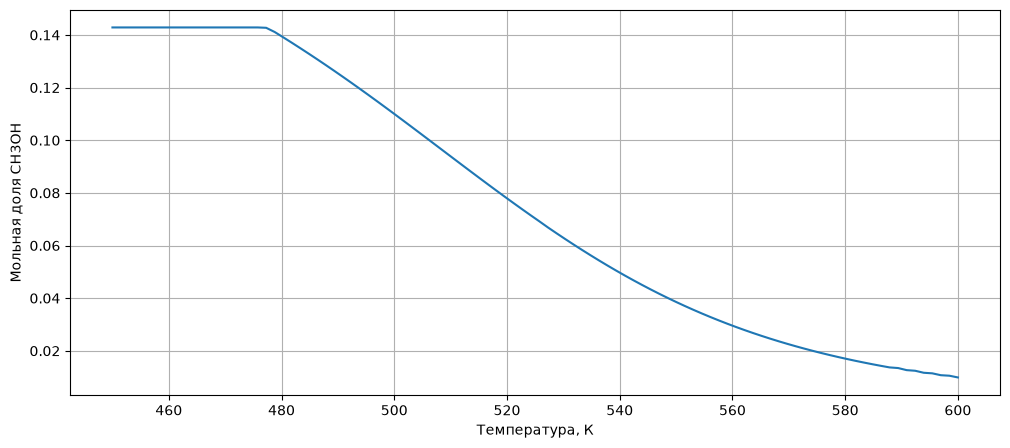

In [55]:
K1_523 = 2.0*10**-4
K2_523 = 1.2 * 10**-2
dH1 = -90.6*10**3
dH2 = 41.2*10**3
R = 8.314
T = np.linspace(450, 600, 100)
start = [0.2, 0.2]
bounds = ([1e-6, 1e-6], [1, 1])
sol_K = []
for i in T:
    s1 = -dH1/R*(1/i-1/523)
    s2 = -dH2/R*(1/i-1/523)
    K1_T = (K1_523*np.exp(s1))
    K2_T = (K2_523*np.exp(s2))
    def eq3(v):
        x1, x2 = v
        return [K1_T - (100**-2*(1/(9-2*x1))**-2*x1/((1-x1+x2)*(7-2*x1-x2)**2)),
        K2_T - (x2*(1-x1+x2)/((1-x2)*(7-2*x1-x2)))]
    sol3 = optimize.least_squares(eq3, start, bounds= bounds)
    sol_K.append(sol3.x[0]/(9-2*sol3.x[0]))
    start = sol3.x
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(T, sol_K, linewidth = 1.5)
ax.grid(True)
ax.set_xlabel('Температура, К')
ax.set_ylabel('Мольная доля CH3OH')
plt.show()

## ⏳ Задание 3

При фотохимическом облучении соединение **A** обратимо изомеризуется в **B**,
который затем необратимо циклизуется в продукт **C**:

$$A \underset{k_{-1}}{\overset{k_1}{\rightleftharpoons}} B \xrightarrow{k_2} C$$

Все стадии - первого порядка. Начальная концентрация $[A]_0 = 0.100$ М,
$[B]_0 = [C]_0 = 0$. Экспериментально измерены концентрации всех трёх веществ
в разные моменты времени (данные в ячейке ниже).

Вам нужно:
* Записать систему дифференциальных уравнений для $[A]$, $[B]$, $[C]$ и
  оформить её в виде функции для `solve_ivp`.
* С помощью `curve_fit` поверх `solve_ivp` найти константы $k_1$, $k_{-1}$,
  $k_2$ (мин⁻¹) и их стандартные погрешности.
* Построить график(и) зависимости концентрации веществ от времени: экспериментальные точки + теоретические кривые.
* Рассчитать константу равновесия изомеризации $K = k_1/k_{-1}$ и её
  погрешность. 
  
  $\frac{\sigma_K}{K} = \sqrt{\left(\frac{\sigma_{k_1}}{k_1}\right)^2 + \left(\frac{\sigma_{k_{-1}}}{k_{-1}}\right)^2}$
* В какой момент времени концентрация промежуточного изомера **B**
  максимальна и чему она равна?

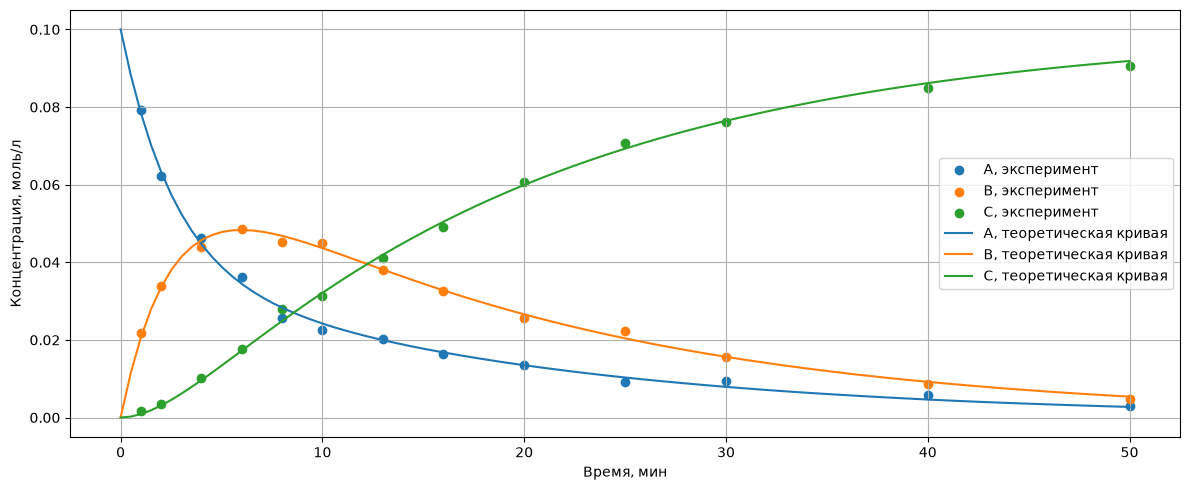

In [ ]:
import numpy as np

# Экспериментальные данные: время (мин) и концентрации (моль/л)
t_exp = np.array([1, 2, 4, 6, 8, 10, 13, 16, 20, 25, 30, 40, 50])
A_exp = np.array([0.0793, 0.0623, 0.0463, 0.0363, 0.0257, 0.0225, 0.0203,
                  0.0164, 0.0136, 0.0091, 0.0093, 0.0059, 0.0029])
B_exp = np.array([0.0219, 0.0338, 0.0440, 0.0487, 0.0453, 0.0449, 0.0381,
                  0.0326, 0.0256, 0.0223, 0.0155, 0.0086, 0.0049])
C_exp = np.array([0.0017, 0.0036, 0.0101, 0.0177, 0.0279, 0.0313, 0.0410,
                  0.0490, 0.0607, 0.0708, 0.0761, 0.0848, 0.0906])

A0 = 0.100  # моль/л

def dydt(t, y, k1, k2, k_1):
    A, B, C = y
    dA_dt = -k1 * A + k_1 * B
    dB_dt = k1*A - k_1*B - k2*B
    dC_dt = k2*B
    return [dA_dt, dB_dt, dC_dt]
y_exp = np.concatenate([A_exp, B_exp, C_exp])
y_0 = [0.1, 0, 0]
x_eval=np.linspace(0,50,100)
def kin(x, k1, k2, k_1):
    sol_kin = integrate.solve_ivp(dydt, (0, 50), y_0, args = (k1, k2, k_1), t_eval= x, rtol = 1e-8, atol = 1e-10)
    return np.concatenate([sol_kin.y[0], sol_kin.y[1], sol_kin.y[2]])
fit, pcov = optimize.curve_fit(kin, t_exp, y_exp)
sol_kin_graph = integrate.solve_ivp(dydt, (0, 50), y_0, args=tuple(fit), t_eval= x_eval)
fig, ax = plt.subplots(figsize=(12,5))
ax.scatter(t_exp, A_exp, label='А, эксперимент')
ax.scatter(t_exp, B_exp, label='B, эксперимент')
ax.scatter(t_exp, C_exp, label='C, эксперимент')
ax.plot(sol_kin_graph.t, sol_kin_graph.y[0], label='А, теоретическая кривая')
ax.plot(sol_kin_graph.t, sol_kin_graph.y[1], label='B, теоретическая кривая')
ax.plot(sol_kin_graph.t, sol_kin_graph.y[2], label='C, теоретическая кривая')
ax.set_xlabel('Время, мин')
ax.set_ylabel('Концентрация, моль/л')
ax.grid(True)
ax.legend()
plt.tight_layout()
plt.show()

In [61]:
K = fit[0]/fit[2]
dK = K*np.sqrt((np.sqrt(pcov[0, 0])/fit[0])**2 + (np.sqrt(pcov[2, 2])/fit[2])**2)
print(f'Константа рановесия изомеризации равна {K} +- {dK}')

Константа рановесия изомеризации равна 2.501850389878707 +- 0.15712396095251618


In [104]:
def dBdt(x):
    sol_kin2 = integrate.solve_ivp(dydt, (0, 50), y_0, args = tuple(fit), t_eval= x)
    A, B, C = sol_kin2.y[:, 0]
    return fit[0]*A - fit[2]*B - fit[1]*B
t_max = optimize.fsolve(dBdt, x0=8)
sol_B = integrate.solve_ivp(dydt, (0, 50), y_0, args = tuple(fit), t_eval= t_max)
B_max = sol_B.y[1]
print(f'Максимальная концентрация B равна {round(B_max[0], 5)} моль/л, она достигается при {round(t_max[0], 0)} минутах')

Максимальная концентрация B равна 0.04832 моль/л, она достигается при 6.0 минутах
